<a href="https://colab.research.google.com/github/kredd2506/hyouka/blob/cloud-session/notebooks/nrx_colab_tpu_actual.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# nrx-jax: cloud session on Colab

Runs the accelerator half of the project. Pick the runtime in *Runtime → Change runtime type*:

- **GPU** (L4 or A100): exact pilots, XLA latency and compiler walk (TF32 and true fp32), TensorRT on the same GPU, full BLER sweep, training from scratch.
- **TPU** (v5e-1 or v6e-1): XLA:TPU latency and compiler walk in three precisions, plus a short training run to measure step time. TensorRT, the pilots and the sweeps need a GPU and are skipped. Sionna (PyTorch) runs on the TPU host's CPU.

**L4 sessions 1–3 already did** everything on the GPU list: acceptance #1–#3 are met and TensorRT vs XLA is measured. Re-running on a GPU skips the finished training.

**Before you start**
1. Pick the runtime type (GPU or TPU).
2. Set the options in the next cell.
3. Run all cells (*Runtime → Run all*). Each section prints a short result.

**If Colab disconnects or restarts:** use *Run all* again. Every cell needs the setup cells first, and training resumes from its last checkpoint on Google Drive.

| Section | GPU (L4) | TPU |
|---|---|---|
| 0–2 Setup + tests | 3–5 min | 3–5 min |
| 3 Exact pilots | < 1 min | skipped |
| 4 XLA latency + compiler walk | ~5 min | ~8 min (3 precisions) |
| 5 TensorRT | ~5 min | skipped |
| 6 Full BLER sweep | ~60 min | skipped |
| 7 Training | 30k steps: ~80 min | `TPU_TRAIN_STEPS`: ~5–15 min |
| 8 Trained-model sweep | ~20 min | skipped |


In [1]:
# ---- Options ----
REPO_URL     = "https://github.com/kredd2506/hyouka.git"
BRANCH       = "cloud-session"
USE_DRIVE    = True      # keep checkpoints + results on Google Drive (needed to resume after a disconnect)
RUN_TRT      = True      # section 5
RUN_SWEEP    = False     # section 6 (long; done in session 1)
RUN_TRAIN    = True      # sections 7-8 (longest)
TRAIN_STEPS  = 30000     # notebook reference; e.g. 5000 for a quick run
TPU_TRAIN_STEPS = 300    # TPU: short run in MyDrive/nrx-jax/run_tpu, to measure step time and Sionna wait
PUSH_RESULTS = False     # section 9: needs a GH_TOKEN Colab secret with write access

## 0. Hardware and storage

In [2]:
import os, re, subprocess, pathlib

def sh(cmd):
    return subprocess.run(cmd, shell=True, capture_output=True, text=True).stdout.strip()

def has_tpu():
    # v5e/v6e TPUs appear as /dev/vfio/*, not /dev/accel*, so look for Google's PCI vendor id (0x1ae0),
    # skipping its virtual NIC (device 0x0042).
    for dev in pathlib.Path("/sys/bus/pci/devices").glob("*"):
        try:
            if (dev / "vendor").read_text().strip() == "0x1ae0" and (dev / "device").read_text().strip() != "0x0042":
                return True
        except OSError:
            pass
    return pathlib.Path("/dev/accel0").exists() or "COLAB_TPU_ADDR" in os.environ or "TPU_ACCELERATOR_TYPE" in os.environ

gpu = sh("nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv,noheader")
ACCEL = "gpu" if gpu else ("tpu" if has_tpu() else "cpu")
print("accelerator:", ACCEL, "|", gpu or "no NVIDIA GPU")

if ACCEL == "gpu":
    driver_major = int(gpu.split(",")[1].strip().split(".")[0])
    # torch 2.15 / jax[cuda13] need CUDA 13 -> driver >= 580. Older drivers: torch 2.14.1+cu126 and jax[cuda12].
    CUDA_MODE = "cuda13" if driver_major >= 580 else "cuda12"
    print(f"driver {driver_major} -> {CUDA_MODE}")
else:
    CUDA_MODE = None
    print("No GPU: sections 3, 5, 6, 8 are skipped. TPU runs section 4 and a short section 7.")

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = pathlib.Path("/content/drive/MyDrive/nrx-jax")
else:
    OUT = pathlib.Path("/content/nrx-jax-out")
OUT.mkdir(parents=True, exist_ok=True)
RUN_DIR = OUT / ("run_tpu" if ACCEL == "tpu" else "run1")
print("outputs ->", OUT)

accelerator: tpu | no NVIDIA GPU
No GPU: sections 3, 5, 6, 8 are skipped. TPU runs section 4 and a short section 7.
Mounted at /content/drive
outputs -> /content/drive/MyDrive/nrx-jax


## 1. Get the code
Clones `BRANCH` from GitHub. For a private repo, add a Colab secret `GH_TOKEN` (key icon in the left bar). Alternatively upload a `hyouka.bundle` (from `git bundle create hyouka.bundle main cloud-session`) to `/content`.

In [3]:
REPO = pathlib.Path("/content/hyouka")
if not REPO.exists():
    bundle = pathlib.Path("/content/hyouka.bundle")
    if bundle.exists():
        url = str(bundle)
    else:
        url = REPO_URL
        try:
            from google.colab import userdata
            tok = userdata.get("GH_TOKEN")
            url = REPO_URL.replace("https://", f"https://{tok}@")
        except Exception:
            pass
    r = subprocess.run(f"git clone -q -b {BRANCH} {url} {REPO}", shell=True, capture_output=True, text=True)
    print(r.stderr.replace(url, REPO_URL) or "cloned")
%cd /content/hyouka
!git log --oneline -3

cloned
/content/hyouka
8a29fa9 (HEAD -> cloud-session, origin/cloud-session) Notebook: detect v5e/v6e TPUs (PCI vendor, not /dev/accel0); stop if JAX isn't on the expected device
b88506f Created using Colab
c2a14ba TPU path: notebook runs XLA:TPU in bf16/bf16x3/fp32 plus a short training run; README TPU + Colab instructions


## 2. Environment
`uv` installs Python 3.12 and the exact versions in `uv.lock`, separate from Colab's own Python.

In [4]:
!pip -q install uv
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"   # let Sionna's torch share the GPU with JAX
if CUDA_MODE == "cuda13":
    !uv sync -q --extra cuda
elif CUDA_MODE == "cuda12":
    !uv sync -q
    !uv pip install -q --reinstall "torch==2.14.1" --index-url https://download.pytorch.org/whl/cu126
    !uv pip install -q "jax[cuda12]==0.12.1"
elif ACCEL == "tpu":
    !uv sync -q --extra tpu
else:
    !uv sync -q
os.environ["UV_NO_SYNC"] = "1"   # stop `uv run` from reverting the CUDA-specific installs to uv.lock

!make host-info
!make test

Mon Nov 23 02:10:07 AM UTC 2026
Linux ab6a560bf66c 6.6.159+ #1 SMP Thu Oct 22 03:07:54 UTC 2026 x86_64 x86_64 x86_64 GNU/Linux
/content/hyouka/.venv/lib/python3.12/site-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(
jax 0.12.1 [TpuDevice(id=0, process_index=0, coords=(0,0,0), core_on_chip=0)]
torch 2.15.0+cu132 cuda 13.2 False
flax 0.12.12
uv run python -m nrx.fetch_weights
Downloading...
From: https://drive.google.com/uc?id=1wjBB3U8Cp4a6VMZSrLBYJl6aG5sPoG_I
To: /content/hyouka/weights/reference/neural_receiver_weights

ok /content/hyouka/weights/reference/neural_receiver_weights sha256=efa5c7adfec6…
uv run pytest -q
......F...F                                                      

In [5]:
# Sanity: both frameworks see the accelerator.
!uv run python -c "import jax, torch, sionna.phy; print('jax', jax.devices(), jax.devices()[0].device_kind); print('torch cuda', torch.cuda.is_available()); print('sionna device', sionna.phy.config.device)" 2>&1 | grep -v -E 'jitc|hugepages|warnings.warn'
backend = sh("cd /content/hyouka && uv run python -c 'import jax; print(jax.default_backend())' 2>/dev/null").splitlines()[-1]
assert backend == ACCEL, f"JAX is on {backend}, expected {ACCEL}: stop here, the benchmarks would measure the wrong device"
print("JAX backend OK:", backend)


jax [TpuDevice(id=0, process_index=0, coords=(0,0,0), core_on_chip=0)] TPU v5 lite
torch cuda False
sionna device cpu
JAX backend OK: tpu


## 3. Exact training pilots (CUDA RNG, seed 42)
The pre-trained weights were trained with pilots drawn from the CUDA RNG. The repo ships pilots recovered from the weights; this regenerates the exact ones and counts mismatches.

In [6]:
if ACCEL == "gpu":
    !make pilots-cuda 2>&1 | grep -v jitc | tail -2

## 4. XLA on this accelerator: latency + compiler walk
Same script and fixtures as on the laptop. The deadline is judged on p99 batch latency (B users in one slot).

On GPU, run twice: `default` (XLA allows TF32 convs on Ampere/Ada) and `highest` (true fp32). On TPU, run three times: `default` (one bf16 pass), `high` (bf16×3, about fp32 accuracy) and `highest` (full fp32 emulation, ~6 passes). The time breakdown now ablates parts of the full compiled graph, because isolated-op timings on GPU are mostly dispatch overhead.

In [7]:
PRECS = ["default", "high", "highest"] if ACCEL == "tpu" else ["default", "highest"]
for prec in PRECS:
    !make backends PRECISION={prec} 2>&1 | grep -v jitc | tail -4
    !make compiler PRECISION={prec} 2>&1 | grep -v jitc | grep -E "^## 3|^  fusion|^## 5|^  (full|without|dispatch|⇒)"


slot budget 0.5 ms @ 30 kHz SCS, judged on p99 batch latency
     tpu default B=1    p99     0.379 ms  max|dLLR| 2.1e-01  (meets)
     tpu default B=8    p99     0.590 ms  max|dLLR| 2.4e-01  (misses)
     tpu default B=128  p99     9.149 ms  max|dLLR| 2.5e-01  (misses)
## 3. Optimized HLO: 104 kernels launched per call
  fusion:kLoop×26, copy×19, multiply×17, pad×10, slice×9, add×8, rsqrt×8, custom-call×2, reshape×2, fusion:kOutput×2, log×1
## 5. Where the time goes (ablation inside the full compiled graph, median ms)
  full NRX                                0.342
  without LayerNorm                       0.286
  without the 8 residual convs            0.290
  without both (in/out conv + glue)       0.244
  dispatch floor (jit x+1)                0.203
  ⇒ 8 residual convs ≈ 0.052 ms (15%), 8 LayerNorms ≈ 0.056 ms (16%), dispatch ≈ 59% of a call
slot budget 0.5 ms @ 30 kHz SCS, judged on p99 batch latency
     tpu    high B=1    p99     0.514 ms  max|dLLR| 8.1e-04  (misses)
     tpu  

## 5. TensorRT on the same GPU
ONNX export of the torch reference → TensorRT engines in three modes: **fp32** (TF32 off, compare with XLA `highest`), **tf32** (compare with XLA `default`), **fp16**. Same timing method and fixtures as XLA.

The `tensorrt` wrapper on PyPI is a source package that failed to install in session 1; `make trt-install` takes the prebuilt libs + bindings wheels from NVIDIA's index instead.

In [8]:
if ACCEL == "gpu" and RUN_TRT:
    trt_cuda = "cu13" if CUDA_MODE == "cuda13" else "cu12"
    !make trt-install TRT_CUDA={trt_cuda} 2>&1 | grep -v jitc | tail -3
    !make onnx 2>&1 | grep -v jitc | grep "^B="
    !make trt 2>&1 | grep -v jitc | grep -E "^TensorRT|skipped|Error|p99"

## 6. Full BLER sweep (notebook settings, `max_mc_iter=1000`)
JAX port, torch reference, and both baselines. Resolves BLER 1e-4 (acceptance: ported within 0.2 dB of the notebook). If section 3 found mismatched pilots, a second sweep with the exact CUDA pilots runs too.

In [9]:
if ACCEL == "gpu" and RUN_SWEEP:
    !make sweep 2>&1 | grep -v jitc | tail -9
    n_diff = sh("cd /content/hyouka && uv run python -m nrx.pilots compare assets/pilots_recovered.npy assets/pilots_cuda_seed42.npy 2>/dev/null | grep -o '^[0-9]*'")
    if n_diff and int(n_diff) > 0:
        print(f"{n_diff} pilots differ -> sweeping NRX with exact CUDA pilots")
        !NRX_PILOTS=assets/pilots_cuda_seed42.npy uv run python -m nrx.evaluate --systems jax-ported --out results/ber_bler_ported_cudapilots.csv 2>&1 | grep -v jitc | tail -4

## 7. Train from scratch in JAX
Checkpoints every 1k steps to Drive. After a disconnect, re-run sections 0–2 and this cell; it resumes. Session 1 left a 5k-step checkpoint in `MyDrive/nrx-jax/run1`, so this continues from there (~70 min on an L4 for the remaining 25k). `wait_ms` in `train_log.csv` shows if Sionna data generation is the bottleneck.

**TPU:** runs `TPU_TRAIN_STEPS` steps into `MyDrive/nrx-jax/run_tpu`. Sionna generates the batches on the host CPU here, so the interesting number is `wait_ms` against the TPU step time.

In [10]:
if ACCEL == "gpu" and RUN_TRAIN:
    !make train RUN={RUN_DIR} STEPS={TRAIN_STEPS} 2>&1 | grep -v jitc | grep -E "step|resumed|Error|assert"
elif ACCEL == "tpu" and RUN_TRAIN:
    !make train RUN={RUN_DIR} STEPS={TPU_TRAIN_STEPS} 2>&1 | grep -v jitc | grep -E "step|resumed|Error|assert"


uv run python -m nrx.train --steps 300 --ckpt-dir /content/drive/MyDrive/nrx-jax/run_tpu
step    100/300  rate -0.3197  step 24.2 ms  traces 1
step    200/300  rate -0.0151  step 24.2 ms  traces 1
step    300/300  rate -0.0082  step 24.2 ms  traces 1
make: *** [Makefile:61: train] Error 134


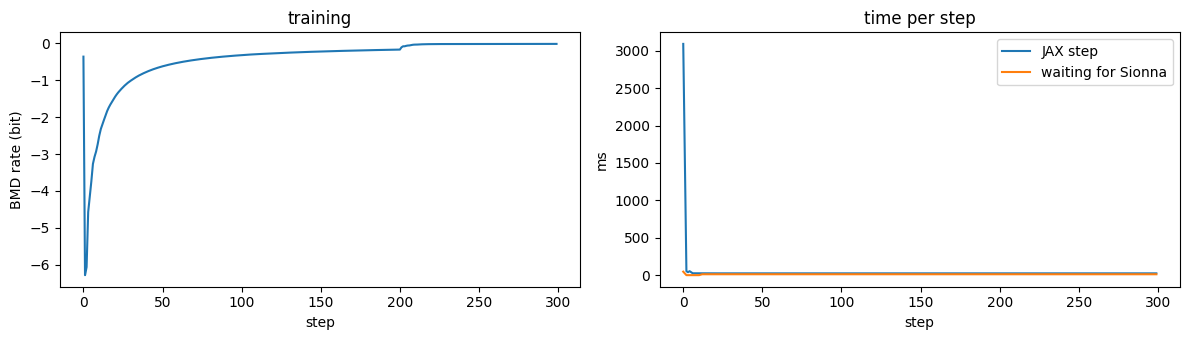

steps 300, final rate -0.1143, median step 24.1 ms, median wait 12.1 ms


In [11]:
# Training curve
import pandas as pd, matplotlib.pyplot as plt
log = RUN_DIR / "train_log.csv"
if log.exists():
    df = pd.read_csv(log)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(df.step, df.rate.rolling(200, min_periods=1).mean()); ax[0].set(xlabel="step", ylabel="BMD rate (bit)", title="training")
    ax[1].plot(df.step, df.step_ms.rolling(200, min_periods=1).median(), label="JAX step"); ax[1].plot(df.step, df.wait_ms.rolling(200, min_periods=1).median(), label="waiting for Sionna")
    ax[1].set(xlabel="step", ylabel="ms", title="time per step"); ax[1].legend()
    plt.tight_layout(); plt.savefig("results/train_curve.png", dpi=120); plt.show()
    print(f"steps {len(df)}, final rate {df.rate.tail(500).mean():.4f}, median step {df.step_ms.median():.1f} ms, median wait {df.wait_ms.median():.1f} ms")

## 8. Evaluate the trained model

In [12]:
if ACCEL == "gpu" and RUN_TRAIN:
    !make eval-trained RUN={RUN_DIR} 2>&1 | grep -v jitc | tail -6

## 9. Summary and save

In [13]:
import json, pandas as pd
R = pathlib.Path("results")

def jsonl(p):
    return pd.DataFrame([json.loads(l) for l in open(p)]) if p.exists() else pd.DataFrame()

xla = jsonl(R / "backend_latency.jsonl")
trt = jsonl(R / "trt_latency.jsonl")
rows = []
if not xla.empty:
    for _, r in xla[xla.backend != "cpu"].iterrows():
        prec = r.get("precision", "default")
        prec = "default" if prec is None or prec != prec else prec
        names = {"gpu": {"default": "tf32", "high": "tf32", "highest": "fp32"},
                 "tpu": {"default": "bf16", "high": "bf16x3", "highest": "fp32"}}
        prec = f"{names.get(r.backend, {}).get(prec, 'fp32')} (xla {prec})"
        rows.append(dict(stack=f"XLA {r.backend} {r.device} (jax {r.jax})", precision=prec, B=r.batch, p50_ms=r.p50_ms, p99_ms=r.p99_ms, max_llr_err=r.max_abs_llr_err))
if not trt.empty:
    for _, r in trt.iterrows():
        rows.append(dict(stack=f"TensorRT {r.trt}", precision=r.precision, B=r.batch, p50_ms=r.p50_ms, p99_ms=r.p99_ms, max_llr_err=r.max_abs_llr_err))
if rows:
    print("Latency, same fixtures (deadline 0.5 ms on p99):")
    table = pd.DataFrame(rows).drop_duplicates(["stack", "precision", "B"], keep="last")  # latest run per setting
    display(table.sort_values(["B", "stack", "precision"]).reset_index(drop=True))

!uv run python -m nrx.evaluate --summary results/reference.csv results/ber_bler_ported.csv results/ber_bler_ported_cudapilots.csv results/ber_bler_trained.csv 2>&1 | grep -v jitc

Latency, same fixtures (deadline 0.5 ms on p99):


,stack,precision,B,p50_ms,p99_ms,max_llr_err
0,TensorRT 11.5.0.63,fp32,1,0.5349,0.5468,0.000053
1,TensorRT 11.5.0.63,tf32,1,0.5399,0.5530,0.000053
2,XLA METAL Metal (jax 0.4.34),fp32 (xla default),1,1.2540,1.3440,0.000037
3,XLA gpu NVIDIA L4 (jax 0.12.1),fp32 (xla highest),1,0.8020,0.8670,0.000018
4,XLA gpu NVIDIA L4 (jax 0.12.1),tf32 (xla default),1,0.8050,0.8690,0.000021
5,XLA tpu TPU v5 lite (jax 0.12.1),bf16 (xla default),1,0.3380,0.3790,0.211800
6,XLA tpu TPU v5 lite (jax 0.12.1),bf16x3 (xla high),1,0.4220,0.5140,0.000812
7,XLA tpu TPU v5 lite (jax 0.12.1),fp32 (xla highest),1,0.5090,0.6380,0.000034
8,TensorRT 11.5.0.63,fp32,8,2.8913,2.9948,0.000040
9,TensorRT 11.5.0.63,tf32,8,1.7877,1.8549,0.009435


/content/hyouka/.venv/lib/python3.12/site-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(
file:system                                    @1e-02   @1e-03   @1e-04
reference:baseline-perfect-csi                  -1.30    -0.71     0.55
reference:baseline-ls-estimation                 2.58     3.36     5.05
reference:neural-receiver                       -1.03     0.14     2.21
ber_bler_ported:jax-ported                      -1.03     0.21     2.33
ber_bler_ported:torch-ref                       -1.03     0.21     2.33
ber_bler_ported:baseline-perfect-csi            -1.30    -0.64     0.38
ber_bler_ported:baseline-ls-estimation           2.54     3.44     5.00
ber_bler_ported_cudapilot

In [14]:
# Save everything to Drive (or /content) and offer a zip download.
import shutil, time
stamp = time.strftime("%Y%m%d-%H%M")
dest = OUT / f"results-{stamp}"
shutil.copytree("results", dest, ignore=shutil.ignore_patterns("*.onnx"))
for f in ["assets/pilots_cuda_seed42.npy"]:
    if pathlib.Path(f).exists(): shutil.copy(f, dest)
if (RUN_DIR / "train_log.csv").exists(): shutil.copy(RUN_DIR / "train_log.csv", dest)
shutil.make_archive(f"/content/nrx-results-{stamp}", "zip", dest)
print("saved", dest)
from google.colab import files
files.download(f"/content/nrx-results-{stamp}.zip")

saved /content/drive/MyDrive/nrx-jax/results-20261123-0214


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# Optional: commit results to the cloud-session branch.
if PUSH_RESULTS:
    from google.colab import userdata
    tok = userdata.get("GH_TOKEN")
    if (RUN_DIR / "train_log.csv").exists():
        shutil.copy(RUN_DIR / "train_log.csv", "results/train_log.csv")
    msg = f"Cloud results: Colab {gpu.split(',')[0] if gpu else ACCEL}"
    push_url = REPO_URL.replace("https://", f"https://{tok}@")
    !git config user.name "nrx-colab" && git config user.email "nrx-colab@users.noreply.github.com"
    !git add results assets && git commit -qm "$msg"
    r = subprocess.run(f"git push -q {push_url} HEAD:{BRANCH}", shell=True, capture_output=True, text=True)
    print((r.stderr or "pushed").replace(tok, "***"))